# IBM Quantum | Vishnu Institute of Technology
## Qiskit Fall Fest 2026
### Challenge 3: Can you change the correlation?

---

### **Problem Statement**
Two qubits can be prepared in a state where their measurement outcomes are strongly correlated.
Your task is to modify a two-qubit circuit and investigate whether you can change the relationship between the two measurement outcomes.

### **Your Task**
1. Create a two-qubit quantum circuit.
2. Start from the Bell-state circuit demonstrated during the workshop.
3. Add or modify one quantum gate.
4. Measure both qubits.
5. Execute the circuit for 100 shots.
6. Observe the measurement results.
7. Display the results using a histogram.
8. Compare the results with the original circuit.
9. Explain how the modification changed the measurement outcomes.

### **Design Constraints**
- Use exactly 2 qubits.
- Measure both qubits.
- Start from the Bell-state circuit.
- Add or modify only one quantum gate.
- Use no more than 4 quantum gates before measurement.
- Be created and executed using Qiskit.
- Use 100 shots.

In [1]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

simulator = AerSimulator()
shots = 100
print("Qiskit initialized successfully!")

Qiskit initialized successfully!


---
## 1. Think Before You Run (Predictions)

### **Original Circuit (Bell State $|\Phi^+\rangle$):**
- State preparation: Starts in $|00\rangle$. Applying $H$ on qubit 0 gives $\frac{1}{\sqrt{2}}(|0\rangle + |1\rangle) \otimes |0\rangle = \frac{|00\rangle + |10\rangle}{\sqrt{2}}$.
- Applying CNOT ($CX$) with control qubit 0 and target qubit 1 entangles them:
  $$|\Phi^+\rangle = \frac{|00\rangle + |11\rangle}{\sqrt{2}}$$
- **Prediction:** Outcomes **00 and 11** will dominate (~50% each). Outcomes 01 and 10 will have 0 counts.

### **Modified Circuit (Adding an $X$ gate on Qubit 1):**
- By adding a Pauli-$X$ gate on qubit 1 after the CNOT gate:
  $$X_1 |\Phi^+\rangle = X_1 \left(\frac{|00\rangle + |11\rangle}{\sqrt{2}}\right) = \frac{|01\rangle + |10\rangle}{\sqrt{2}} = |\Psi^+\rangle$$
- **Prediction:** The correlation changes from identical ($00, 11$) to **opposite / anti-correlated ($01, 10$)**!
- **Expected for 100 shots:** Outcomes **01 and 10** will dominate (~50% each), and outcomes 00 and 11 will have 0 counts.

In [2]:
# 1. Original Bell State Circuit
qc_orig = QuantumCircuit(2, 2, name="Original_Bell")
qc_orig.h(0)           # Hadamard on qubit 0
qc_orig.cx(0, 1)       # CNOT from qubit 0 to qubit 1
qc_orig.measure([0, 1], [0, 1])

print("--- Original Bell State Circuit ---")
print(qc_orig.draw('text'))

counts_orig = simulator.run(qc_orig, shots=shots).result().get_counts()
print("Original Results (100 shots):", counts_orig)

--- Original Bell State Circuit ---
     ┌───┐     ┌─┐   
q_0: ┤ H ├──■──┤M├───
     └───┘┌─┴─┐└╥┘┌─┐
q_1: ─────┤ X ├─╫─┤M├
          └───┘ ║ └╥┘
c: 2/═══════════╩══╩═
                0  1 
Original Results (100 shots): {'11': 52, '00': 48}


In [3]:
# 2. Modified Circuit: Added 1 X gate on qubit 1 (total 3 gates <= 4 limit)
qc_mod = QuantumCircuit(2, 2, name="Modified_Correlation")
qc_mod.h(0)
qc_mod.cx(0, 1)
qc_mod.x(1)            # Adding one X gate to change correlation
qc_mod.measure([0, 1], [0, 1])

print("--- Modified Circuit (+ X Gate on Qubit 1) ---")
print(qc_mod.draw('text'))

counts_mod = simulator.run(qc_mod, shots=shots).result().get_counts()
print("Modified Results (100 shots):", counts_mod)

--- Modified Circuit (+ X Gate on Qubit 1) ---
     ┌───┐          ┌─┐   
q_0: ┤ H ├──■───────┤M├───
     └───┘┌─┴─┐┌───┐└╥┘┌─┐
q_1: ─────┤ X ├┤ X ├─╫─┤M├
          └───┘└───┘ ║ └╥┘
c: 2/════════════════╩══╩═
                     0  1 
Modified Results (100 shots): {'01': 56, '10': 44}


---
## 2. Histograms Comparison

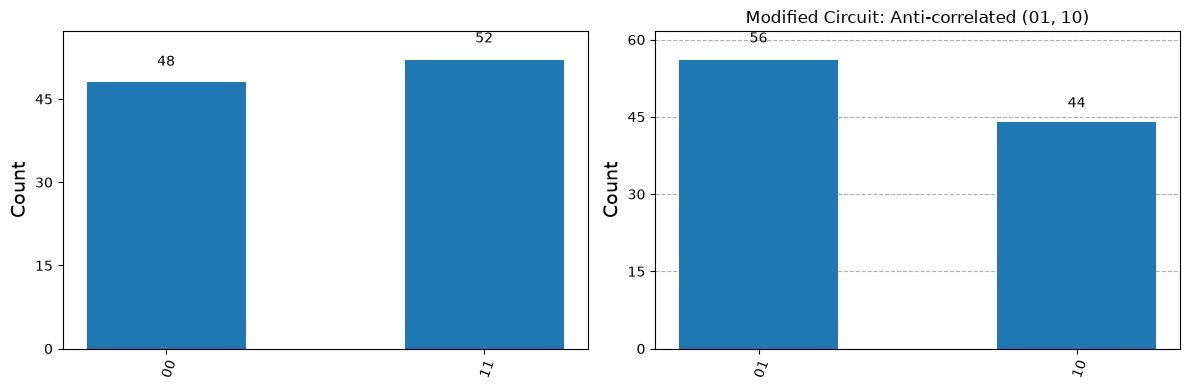

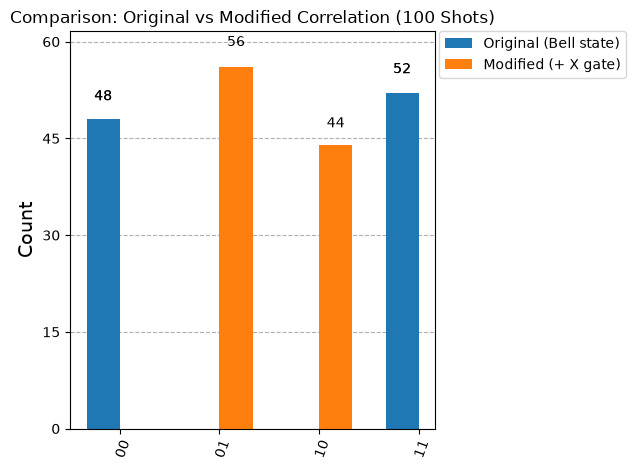

In [4]:
# Side-by-side Histograms
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_histogram(counts_orig, ax=axes[0], title="Original Circuit: Correlated (00 & 11)")
plot_histogram(counts_mod, ax=axes[1], title="Modified Circuit: Anti-correlated (01 & 10)")
plt.tight_layout()
plt.show()

# Combined Histogram
plot_histogram([counts_orig, counts_mod], 
               legend=["Original (|Phi+>)", "Modified (|Psi+>)"], 
               title="Comparison: Changing Quantum Correlation (100 Shots)")
plt.show()

---
## 3. Explanation of Observed Change

| Circuit | Gates Applied | Quantum State | Dominant Outcomes | Actual Counts (100 Shots) |
| :--- | :--- | :--- | :--- | :--- |
| **Original Circuit** | $H(0) \to CX(0, 1)$ | $|\Phi^+\rangle = \frac{|00\rangle + |11\rangle}{\sqrt{2}}$ | `00` and `11` | {'11': 52, '00': 48} |
| **Modified Circuit** | $H(0) \to CX(0, 1) \to X(1)$ | $|\Psi^+\rangle = \frac{|01\rangle + |10\rangle}{\sqrt{2}}$ | `01` and `10` | {'01': 56, '10': 44} |

### **Detailed Explanation:**
1. **Original Circuit:** The Hadamard gate creates superposition on qubit 0, and the CNOT gate establishes entanglement such that qubit 1 copies the state of qubit 0. Hence, both qubits are always measured to have identical values (`00` or `11`).
2. **How the Modification Changed the Relationship:** 
   - We added a single Pauli-$X$ (NOT) gate on qubit 1.
   - The $X$ gate inverts the value of qubit 1 without breaking the entanglement.
   - As a result, whenever qubit 0 is 0, qubit 1 is now flipped to 1 (outcome `01`); whenever qubit 0 is 1, qubit 1 is flipped to 0 (outcome `10`).
   - This successfully transformed the correlation from **perfectly identical** ($00, 11$) to **perfectly opposite** ($01, 10$).